# Hybridization : Hybrid Models for Forecasting Sri Lanka Telecom Closing Prices

This notebook investigates whether combining two models improves the forecast of SLT’s next trading day closing price.

- **Experiment 1 — ARIMA + Random Forest:** ARIMA predicts the next closing price. Random Forest estimates a correction using errors from earlier forecasts.
- **Experiment 2 — Random Forest + Artificial Neural Network:** Both models predict the next closing price from a table of recent prices and moving averages. Their predictions are averaged to produce the hybrid forecast.

Each hybrid is compared with its individual models and the previous-close baseline on the same test dates. Forecast accuracy is measured using MAE and RMSE in Sri Lankan rupees (LKR). Lower values indicate smaller errors.

In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Upload the daily CSV.
csv_file = Path("TeleCom_2009_2023_Daily.csv")

if not csv_file.exists():
    from google.colab import files
    files.upload()

# Read the trading date and closing price.
prices = pd.read_csv(csv_file, usecols=["Date", "Price"])
prices["Date"] = pd.to_datetime(prices["Date"], format="%m/%d/%Y")
prices["Price"] = pd.to_numeric(prices["Price"])
prices = prices.sort_values("Date").reset_index(drop=True)

#  same inputs used in Notebook 1.
data = prices.copy()
data["Previous_Close"] = data["Price"].shift(1)
data["Close_5_Days_Ago"] = data["Price"].shift(5)
data["Average_5_Days"] = data["Price"].rolling(5).mean()
data["Average_10_Days"] = data["Price"].rolling(10).mean()

# The target is the closing price on the next recorded trading day.
data["Target_Date"] = data["Date"].shift(-1)
data["Next_Close"] = data["Price"].shift(-1)
data = data.dropna().reset_index(drop=True)

display(data.head())

,Date,Price,Previous_Close,Close_5_Days_Ago,Average_5_Days,Average_10_Days,Target_Date,Next_Close
0,2009-07-22,47.69,47.50,45.5,46.438,46.169,2009-07-23,47.25
1,2009-07-23,47.25,47.69,45.0,46.888,46.244,2009-07-24,47.00
2,2009-07-24,47.00,47.25,45.5,47.188,46.344,2009-07-27,47.50
3,2009-07-27,47.50,47.00,46.5,47.388,46.519,2009-07-28,47.50
4,2009-07-28,47.50,47.50,47.5,47.388,46.694,2009-07-29,47.50


### Preparing the inputs

Each row represents a forecast made after the market closes. The current price, earlier prices, and moving averages are known at that point. The `Next_Close` column contains the answer the models are trying to predict. For example, if Friday and Monday are consecutive trading dates in the dataset, Friday’s inputs are used to predict Monday’s close.

In [10]:
features = [
    "Price",
    "Previous_Close",
    "Close_5_Days_Ago",
    "Average_5_Days",
    "Average_10_Days",
]

# Keep the earliest 80% for training and the latest 20% for testing.
split = int(len(data) * 0.80)
train = data.iloc[:split]
test = data.iloc[split:]

X_train = train[features]
y_train = train["Next_Close"]
X_test = test[features]
actual = test["Next_Close"].to_numpy()

# Baseline forecast: the next close equals the current close.
baseline = test["Price"].to_numpy()

print("Training rows:", len(train))
print("Test rows:", len(test))
print("First test target date:", test["Target_Date"].min().date())
print("Last test target date:", test["Target_Date"].max().date())

Training rows: 2583
Test rows: 646
First test target date: 2020-07-28
Last test target date: 2023-04-12


In [11]:
def show_results(title, forecasts):
    # Put actual prices and forecasts side by side for each test date.
    predictions = pd.DataFrame({
        "Date": test["Target_Date"].to_numpy(),
        "Actual": actual,
        "Previous close": baseline,
        **forecasts,
    })

    # Calculate both error measures over the full test period.
    rows = []
    for name in ["Previous close", *forecasts]:
        rows.append({
            "Model": name,
            "MAE (LKR)": mean_absolute_error(actual, predictions[name]),
            "RMSE (LKR)": np.sqrt(mean_squared_error(actual, predictions[name])),
        })

    scores = pd.DataFrame(rows).sort_values("MAE (LKR)", ignore_index=True)
    display(scores.round(3))

    predictions.plot(
        x="Date",
        figsize=(12, 4),
        title=title,
        ylabel="Closing price (LKR)",
        grid=True,
    )
    plt.tight_layout()
    plt.show()

    return predictions, scores

## Experiment 1 — ARIMA + Random Forest for time-series forecasting

ARIMA uses the sequence of closing prices to make a forecast. Random Forest then looks at the five most recent ARIMA errors and estimates how much the next forecast may need to change.

Forecast error is calculated as actual price minus predicted price. For example, if ARIMA predicts LKR 50 and the actual close is LKR 52, the error is +LKR 2. On a future trading day, if ARIMA predicts LKR 54 and Random Forest estimates a correction of +LKR 1, the hybrid forecast becomes LKR 55.

The experiment checks whether these corrections improve accuracy over ARIMA alone.

Why time-series forecasting was used: The dataset records SLT’s closing share price over successive trading days. Since the aim is to predict the next trading day’s close using prices already observed, the order of the records matters. ARIMA uses this price history to make a forecast. Comparing ARIMA alone with ARIMA + Random Forest shows whether patterns in earlier forecast errors can help improve the next prediction. Earlier dates are used for training and later dates for testing.

In [12]:
from statsmodels.tsa.arima.model import ARIMA

# Collect all recorded closing prices before the first test target date.
first_test_date = test["Target_Date"].iloc[0]
history = prices.loc[prices["Date"] < first_test_date, "Price"].to_numpy()

# Fit ARIMA on the first half of this history.
# Keep the second half to collect realistic errors for Random Forest.
midpoint = len(history) // 2
arima = ARIMA(history[:midpoint], order=(1, 1, 1)).fit()

# Each fitted value below is a one-step forecast made before that close is observed.
later_history = history[midpoint:]
calibration = arima.extend(later_history)
training_errors = later_history - np.asarray(calibration.fittedvalues)

# Continue through the test dates, updating ARIMA after each observed close.
test_run = calibration.extend(actual)
arima_forecast = np.asarray(test_run.fittedvalues)

print("First test date:", first_test_date.date())
print("ARIMA forecast:", round(arima_forecast[0], 2), "LKR")
print("Actual closing price:", round(actual[0], 2), "LKR")

First test date: 2020-07-28
ARIMA forecast: 28.47 LKR
Actual closing price: 28.2 LKR


,Model,MAE (LKR),RMSE (LKR)
0,ARIMA,1.156,2.245
1,Previous close,1.166,2.173
2,ARIMA + RF,1.190,2.217
3,Random Forest,3.346,8.344


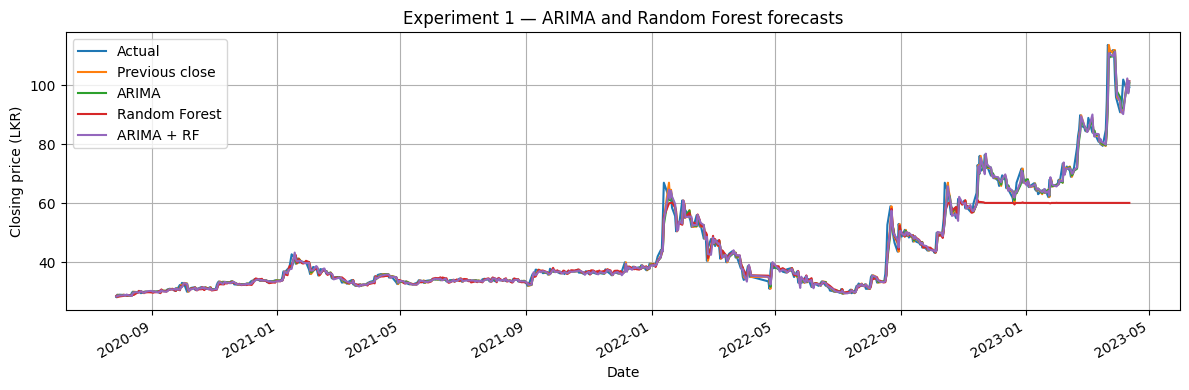

In [13]:
# Calculate the error made by ARIMA on each test date.
test_errors = actual - arima_forecast
errors = pd.Series(np.concatenate([training_errors, test_errors]))

# Shift by at least one day so today's prediction uses only earlier errors.
error_inputs = pd.DataFrame({
    f"Error_{lag}_days_ago": errors.shift(lag)
    for lag in range(1, 6)
})

# Train the correction model using only errors from before the test period.
boundary = len(training_errors)
correction_rf = RandomForestRegressor(n_estimators=100, random_state=42)
correction_rf.fit(
    error_inputs.iloc[5:boundary],
    errors.iloc[5:boundary],
)

# Add the estimated correction to each ARIMA forecast.
corrections = correction_rf.predict(error_inputs.iloc[boundary:])
arima_rf_forecast = arima_forecast + corrections

# Train a standalone RF on price features for comparison.
# This RF predicts a price, while the RF above predicts an error.
price_rf = RandomForestRegressor(n_estimators=100, random_state=42)
price_rf.fit(X_train, y_train)
rf_forecast = price_rf.predict(X_test)

arima_predictions, arima_results = show_results(
    "Experiment 1 — ARIMA and Random Forest forecasts",
    {
        "ARIMA": arima_forecast,
        "Random Forest": rf_forecast,
        "ARIMA + RF": arima_rf_forecast,
    },
)

**Interpretation of result:** ARIMA alone had an MAE of LKR 1.156, slightly lower than the previous-close baseline of LKR 1.166. The difference was about one cent per share. Adding the Random Forest correction increased MAE to LKR 1.190, so the hybrid made a slightly larger error on average. However, RMSE fell from LKR 2.245 to LKR 2.217. Since RMSE gives more weight to larger errors, the correction improved this measure even though it did not improve average absolute error. ARIMA had the lowest MAE in this experiment, while the previous-close baseline had the lowest RMSE.

## Experiment 2 — Random Forest + ANN for tabular regression

Each row represents one trading day. The inputs include the current closing price, earlier closing prices, and moving averages. The target is the next trading day’s closing price in LKR. Predicting a numerical value from these columns makes this a tabular regression task. Random Forest and the artificial neural network (ANN) each produce a forecast. A 50/50 average gives both models equal weight without choosing a preferred model before testing. For example, if Random Forest predicts LKR 48 and the ANN predicts LKR 52, the hybrid forecast is LKR 50.

,Model,MAE (LKR),RMSE (LKR)
0,Previous close,1.166,2.173
1,ANN,1.547,3.018
2,RF + ANN (50/50),2.244,5.039
3,Random Forest,3.346,8.344


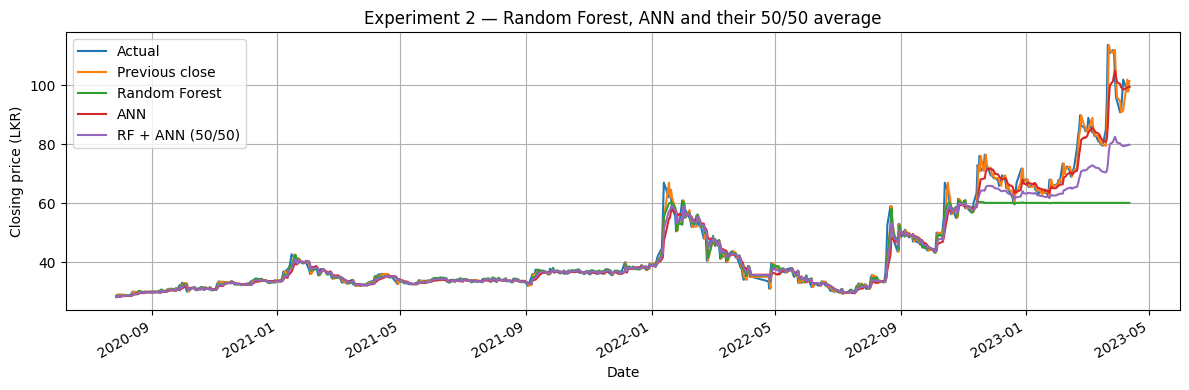

In [14]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Scale the inputs and target using training data.
# The ANN returns its final predictions in LKR.
ann = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(32,),
            max_iter=1000,
            random_state=42,
        ),
    ),
    transformer=StandardScaler(),
)

ann.fit(X_train, y_train)
ann_forecast = ann.predict(X_test)

# Reuse the standalone RF forecast and give both models equal weight.
rf_ann_forecast = (rf_forecast + ann_forecast) / 2

ann_predictions, ann_results = show_results(
    "Experiment 2 — Random Forest, ANN and their 50/50 average",
    {
        "Random Forest": rf_forecast,
        "ANN": ann_forecast,
        "RF + ANN (50/50)": rf_ann_forecast,
    },
)

In [15]:
from google.colab import files

# Save the forecasts used in each hybrid experiment.
arima_predictions.to_csv("02_arima_rf_predictions.csv", index=False)
ann_predictions.to_csv("03_rf_ann_predictions.csv", index=False)

files.download("02_arima_rf_predictions.csv")
files.download("03_rf_ann_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Interpretation of result:** The ANN had an average absolute error of LKR 1.547 per share, compared with LKR 3.346 for Random Forest. The graph shows what happened when the two forecasts were averaged. Near the end of the test period, Random Forest stayed close to LKR 60 while the ANN followed the price rise more closely. When the ANN forecast was around LKR 100, giving both models equal weight put the hybrid forecast around LKR 80. Over the full test period, the hybrid’s MAE of LKR 2.244 was lower than Random Forest’s but higher than the ANN’s. The previous-close baseline had the lowest MAE (LKR 1.166) and RMSE (LKR 2.173) in this experiment.

## Conclusion

**Interpretation of result:** The two hybrids affected forecast accuracy in different ways. Adding Random Forest to ARIMA slightly reduced RMSE but increased MAE. Averaging Random Forest and ANN improved on Random Forest alone, while ANN alone remained more accurate than their average.

Across both experiments, ARIMA alone had the lowest MAE, and the previous-close baseline had the lowest RMSE. For this SLT test period, the strongest forecasting method depended on whether the priority was a smaller average error or a lower penalty for large errors.

# Comparing RF with Other Ensemble Methods (Research)

## 1. RF vs Gradient Boosting (XGBoost, LightGBM, CatBoost)

| Aspect | Random Forest | Gradient Boosting (XGBoost / LightGBM / CatBoost) |
|---|---|---|
| **How it builds trees** | Many deep trees trained in parallel, independently, on bootstrap samples (bagging) | Shallow trees built sequentially, each correcting the previous trees' errors (boosting) |
| **Main effect** | Reduces **variance** | Reduces bias (and variance with regularisation) |
| **Accuracy** | Strong out of the box | Usually higher on tabular data once tuned |
| **Tuning effort** | Low; few sensitive hyperparameters | Higher; learning rate, depth, n_estimators and regularisation interact |
| **Overfitting** | Resistant; more trees rarely hurts | Can overfit if over-boosted; needs early stopping |
| **Noisy data / outliers** | More robust | More sensitive, since it keeps chasing hard examples |
| **Training speed** | Parallelisable | Sequential, though LightGBM and XGBoost are heavily optimised |

### Differences among the boosting libraries
- **XGBoost:** Regularised, robust and widely used. Handles missing values natively and is a strong default.
- **LightGBM:** Very fast on large datasets. Uses leaf-wise tree growth and histogram binning, but can overfit small datasets.
- **CatBoost:** Best for datasets with many categorical features. Handles them natively with ordered target encoding, needs little tuning and works well on small to medium data.


## 2. Strengths and Limitations: Tabular vs Image/Text Data

### Tabular data

**Strengths**
- Handle mixed numeric and categorical features.
- Need little preprocessing: no scaling required, and many handle missing values.
- Capture non-linear relationships and feature interactions automatically.
- Provide feature importance and are fairly interpretable.
- Train quickly on small to medium datasets.

**Limitations**
- Cannot extrapolate beyond the training range (matters for regression and trends).
- Large RF models use a lot of memory and are slower at inference.
- High-cardinality categorical features can cause problems.

### Image/text data

**Strengths**
- **Fast, simple baseline:** RF or XGBoost on TF-IDF features or flattened pixels trains quickly and gives a reference score before trying deep learning.
- **Works on small datasets:** With little labelled data, deep models overfit, while tree ensembles are more stable.
- **Cheap to run:** No GPU needed; trains and runs on ordinary hardware.
- **Accept sparse input:** XGBoost and LightGBM can take sparse TF-IDF / bag-of-words matrices, though linear models often do better on text.
- **Interpretable for text:** Feature importance shows which words drive predictions (e.g. which terms indicate spam).
- **Strong as a final classifier (hybrid approach):** Works well on embeddings extracted by a CNN or Transformer, combining learned features with a tree-based decision layer.
- **Good for mixed data:** Useful when text or image-derived features are combined with tabular fields (e.g. review text features plus customer attributes).

**Limitations**
- Trees treat each feature independently, so they miss local patterns (edges, shapes) and word order or context.
- They cannot learn hierarchical representations the way CNNs or Transformers do.
- Text needs manual feature engineering, which loses meaning.
- Accuracy is generally far below deep learning on large datasets.
